# Machine Learning Project
## Part A: Numerical Regression

**Dataset:** Student Performance

**Models:**
- Linear Regression
- K-Nearest Neighbors (KNN) Regressor

**Objective:**
To build and evaluate regression models that predict students' Performance Index based on their study habits and academic-related features.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
plots_path = "/content/drive/MyDrive/DataSets/Num dataset/plots"
os.makedirs(plots_path, exist_ok=True)

processed_path = "/content/drive/MyDrive/DataSets/Num dataset/Processed"
os.makedirs(processed_path, exist_ok=True)

In [4]:
dataset_path = '/content/drive/MyDrive/DataSets/Num dataset/Student_Performance.csv'
df = pd.read_csv(dataset_path)
print("Original Dataset Shape:", df.shape)
display(df.head())

Original Dataset Shape: (10000, 6)


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [5]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (10000, 6)

Column Names:
['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']

First 5 Rows:


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [6]:
display(df.describe())

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [7]:
display(df.describe(include="object"))

,Extracurricular Activities
count,10000
unique,2
top,No
freq,5052


In [8]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()
print("Numerical Columns:")
print(numerical_columns)

Numerical Columns:
['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']


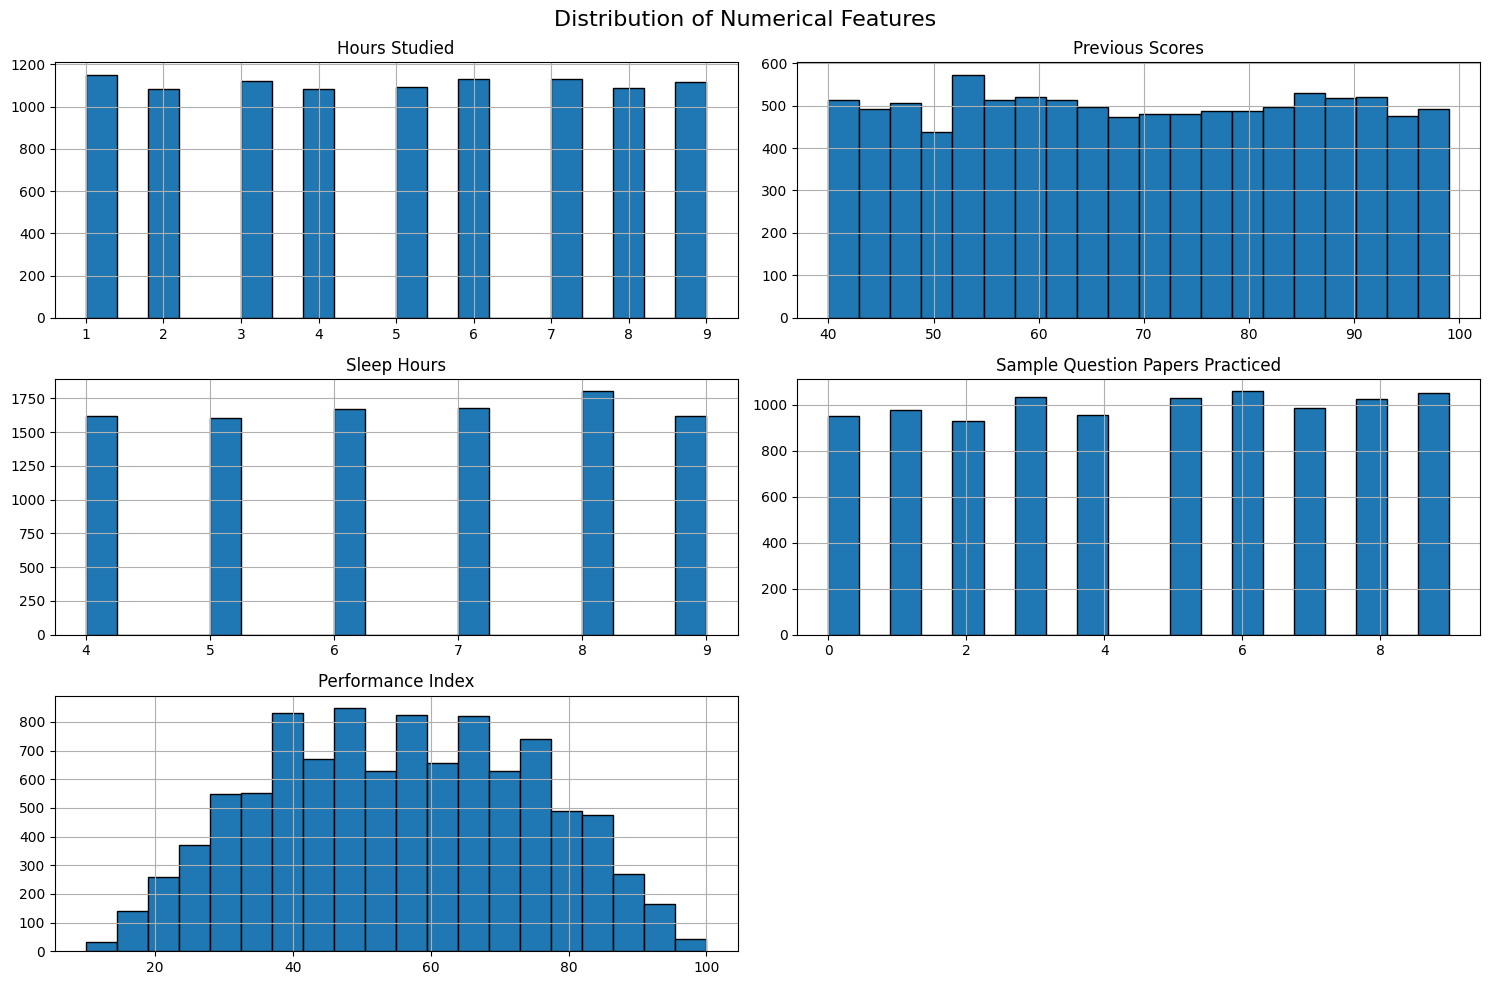

In [9]:
df[numerical_columns].hist(
    figsize=(15, 10),
    bins=20,
    edgecolor="black"
)
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.savefig(
    os.path.join(plots_path, "numerical_histograms.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

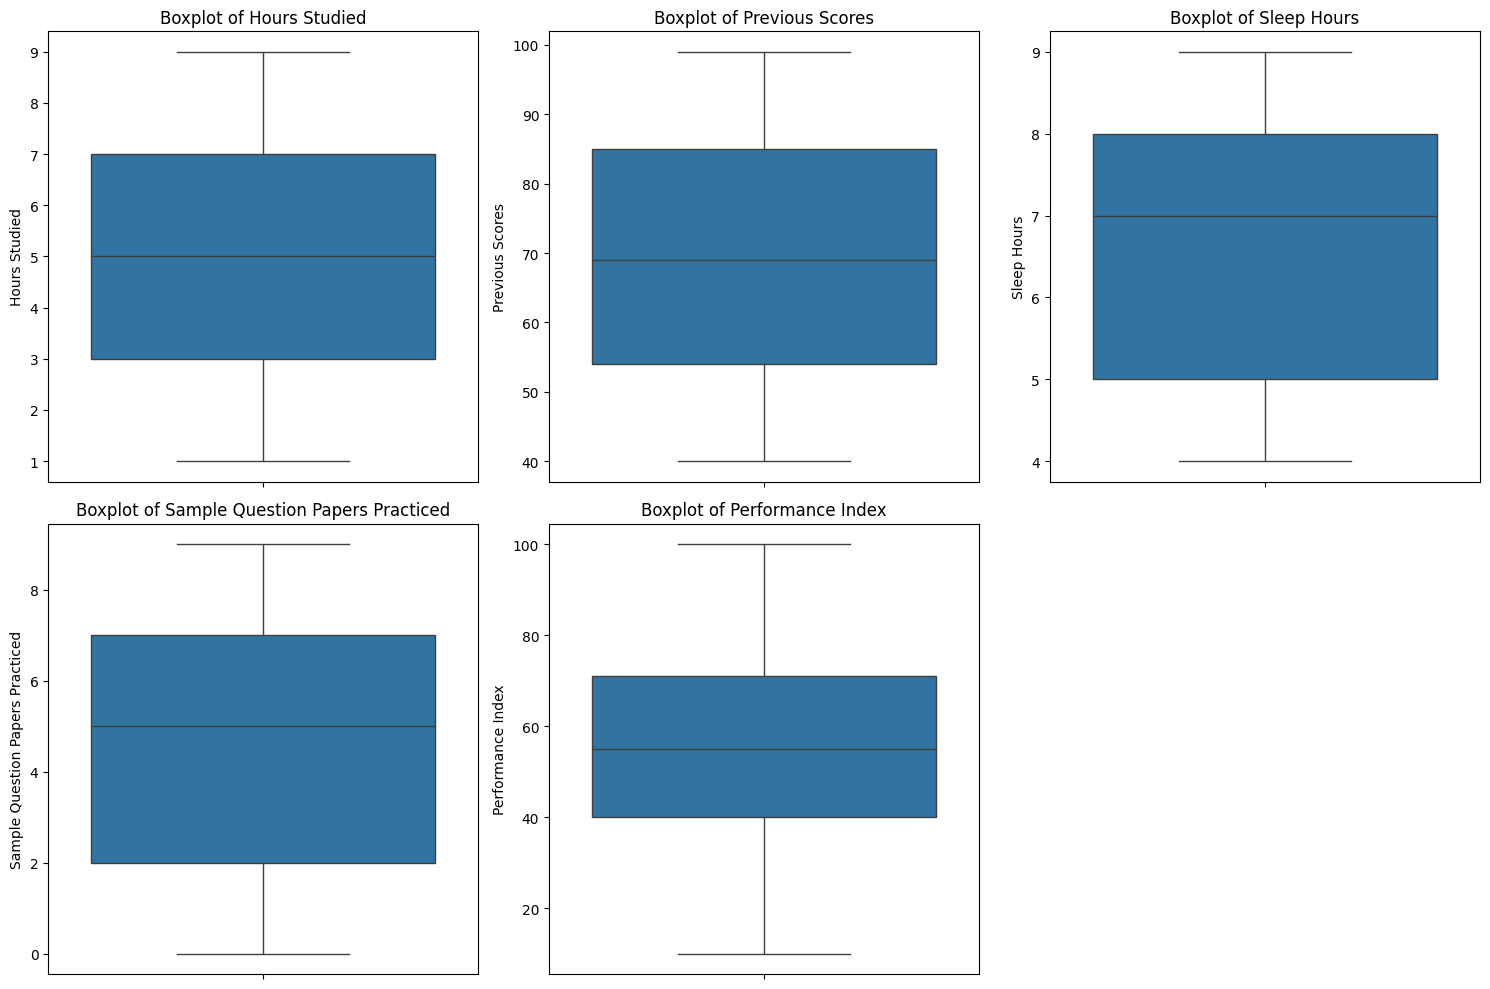

In [10]:
plt.figure(figsize=(15, 10))
for i, column in enumerate(numerical_columns, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[column])
    plt.title(f"Boxplot of {column}")
plt.tight_layout()
plt.savefig(f"{plots_path}/boxplots.png")
plt.show()

In [11]:
outlier_results = []
for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]
    outlier_results.append({
        "Feature": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers Count": len(outliers),
        "Outliers Percentage": (len(outliers) / len(df)) * 100
    })
outlier_summary = pd.DataFrame(outlier_results)
print("Outlier Analysis using IQR Method:")
display(outlier_summary.round(2))
outlier_summary.to_csv(
    os.path.join(processed_path, "outlier_analysis.csv"),
    index=False
)

Outlier Analysis using IQR Method:


,Feature,Lower Bound,Upper Bound,Outliers Count,Outliers Percentage
0,Hours Studied,-3.0,13.0,0,0.0
1,Previous Scores,7.5,131.5,0,0.0
2,Sleep Hours,0.5,12.5,0,0.0
3,Sample Question Papers Practiced,-5.5,14.5,0,0.0
4,Performance Index,-6.5,117.5,0,0.0


In [12]:
correlation_df = df.copy()
correlation_df["Extracurricular Activities"] = (
    correlation_df["Extracurricular Activities"].map({
        "Yes": 1,
        "No": 0
    })
)

In [13]:
correlation_matrix = correlation_df.corr()
display(correlation_matrix)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
Hours Studied,1.000000,-0.012390,0.003873,0.001245,0.017463,0.373730
Previous Scores,-0.012390,1.000000,0.008369,0.005944,0.007888,0.915189
Extracurricular Activities,0.003873,0.008369,1.000000,-0.023284,0.013103,0.024525
Sleep Hours,0.001245,0.005944,-0.023284,1.000000,0.003990,0.048106
Sample Question Papers Practiced,0.017463,0.007888,0.013103,0.003990,1.000000,0.043268
Performance Index,0.373730,0.915189,0.024525,0.048106,0.043268,1.000000


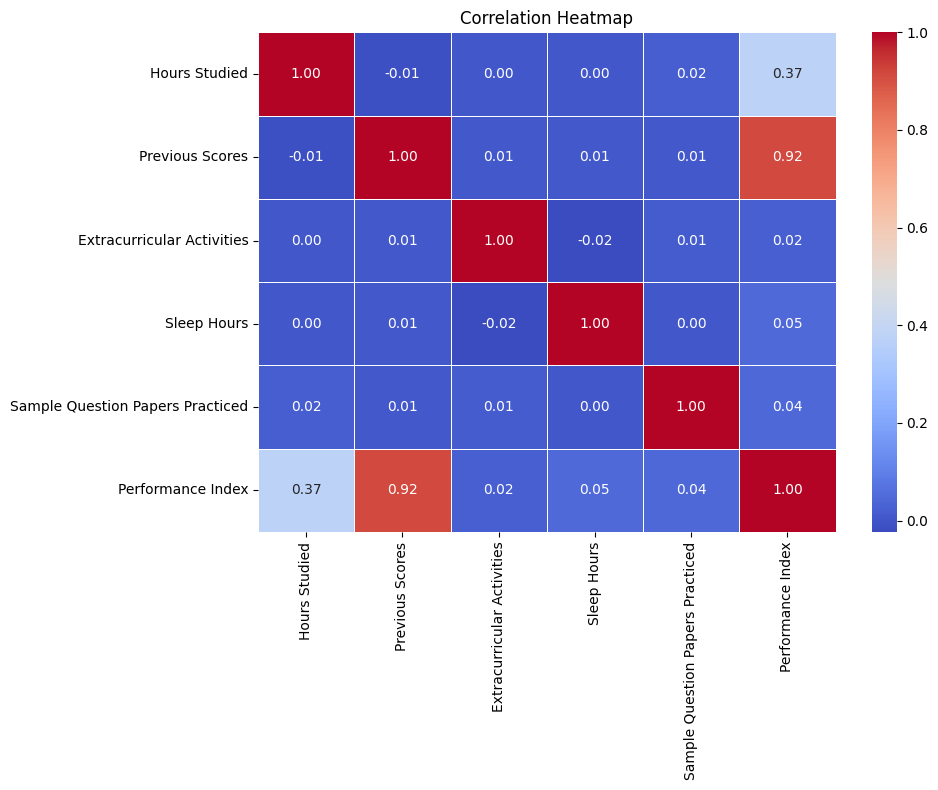

In [14]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(f"{plots_path}/correlation_heatmap.png")
plt.show()

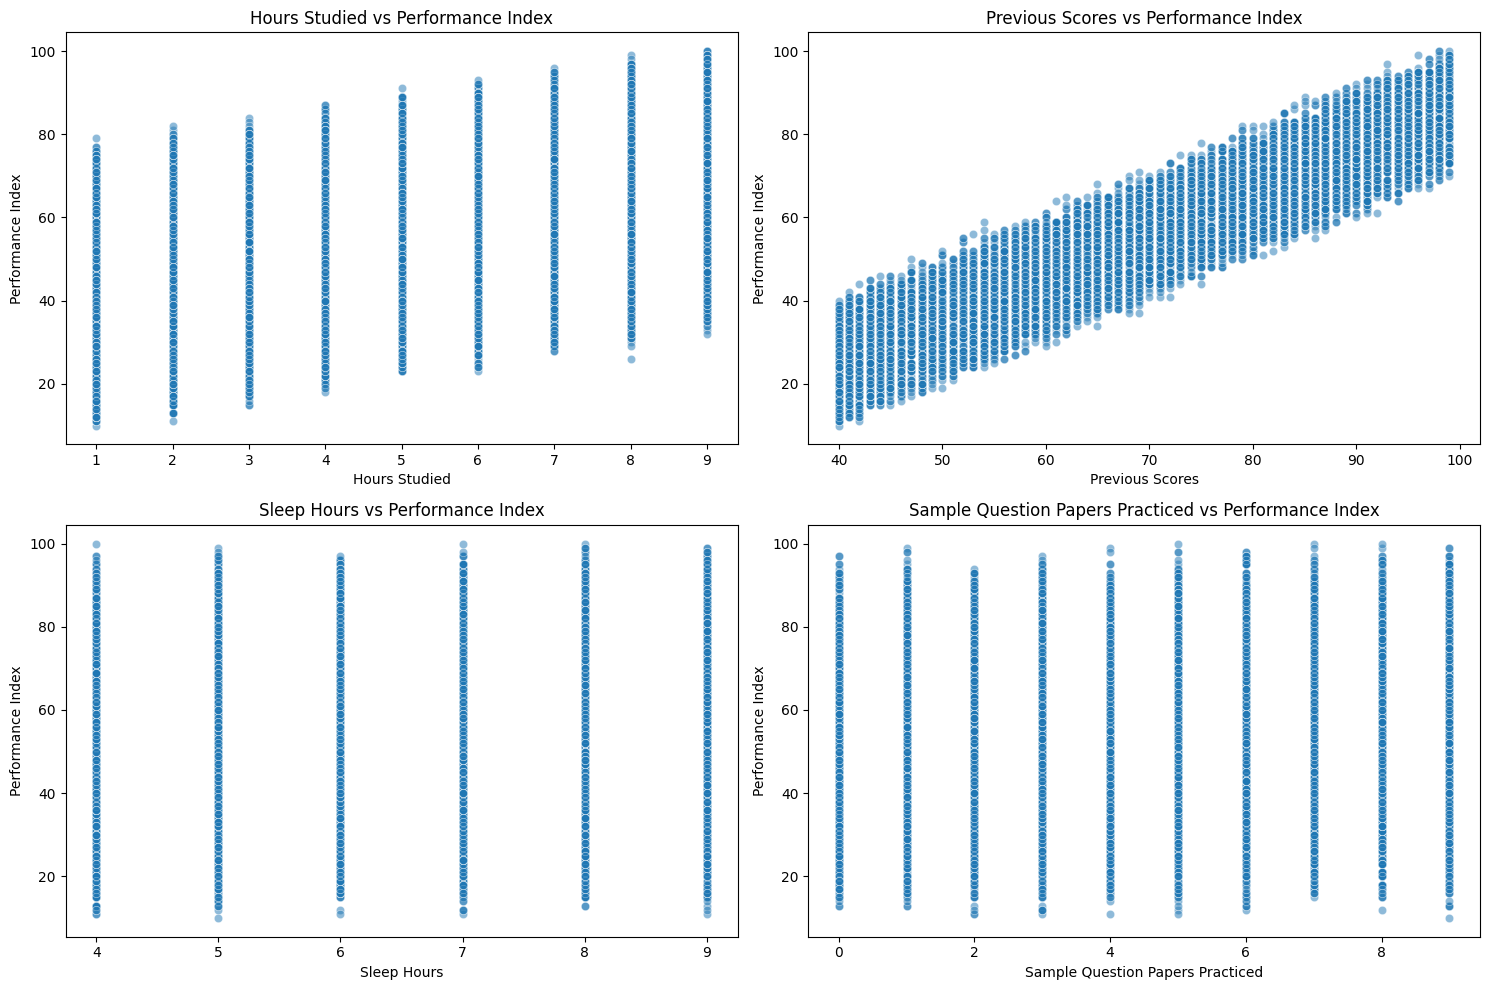

In [15]:
features = [
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced"
]
plt.figure(figsize=(15, 10))
for i, column in enumerate(features, 1):
    plt.subplot(2, 2, i)
    sns.scatterplot(
        x=df[column],
        y=df["Performance Index"],
        alpha=0.5
    )
    plt.title(f"{column} vs Performance Index")
    plt.xlabel(column)
    plt.ylabel("Performance Index")
plt.tight_layout()
plt.savefig(f"{plots_path}/scatter_plots.png")
plt.show()

In [16]:
target_correlation = correlation_matrix["Performance Index"].drop(
    "Performance Index"
)
target_correlation = target_correlation.sort_values(
    ascending=False
)
print("Correlation with Performance Index:")
print(target_correlation)

Correlation with Performance Index:
Previous Scores                     0.915189
Hours Studied                       0.373730
Sleep Hours                         0.048106
Sample Question Papers Practiced    0.043268
Extracurricular Activities          0.024525
Name: Performance Index, dtype: float64


In [17]:
def clean_data(df):
    df = df.copy()
    if df.empty:
        print("Warning: The dataset is empty.")
        return df

    duplicates = df.duplicated().sum()
    if duplicates > 0:
        df = df.drop_duplicates()
        print(f"Removed {duplicates} duplicate rows.")
    else:
        print("No duplicate rows found.")
    missing_values = df.isnull().sum()
    if missing_values.sum() > 0:
        print("Missing values found:")
        for column in df.columns:
            if df[column].isnull().sum() > 0:
                if pd.api.types.is_numeric_dtype(df[column]):
                    median_value = df[column].median()
                    if pd.notna(median_value):
                        df[column] = df[column].fillna(median_value)
                else:
                    mode_value = df[column].mode()
                    if not mode_value.empty:
                        df[column] = df[column].fillna(mode_value[0])
        print("Missing values handling completed.")
    else:
        print("No missing values found.")
    is_not_empty = not df.empty
    no_missing_values = df.isnull().sum().sum() == 0
    no_duplicates = not df.duplicated().any()
    if is_not_empty and no_missing_values and no_duplicates:
        print("Data Validation: Passed")
    else:
        print("Data Validation: Failed")
    print("Data Cleaning Completed Successfully.")
    return df

In [18]:
cleaned_df = clean_data(df)
print("Original data shape:", df.shape)
print("Cleaned data shape:", cleaned_df.shape)
print("\nMissing values:")
print(cleaned_df.isnull().sum())
print("\nDuplicate rows:")
print(cleaned_df.duplicated().sum())
display(cleaned_df.head())

Removed 127 duplicate rows.
No missing values found.
Data Validation: Passed
Data Cleaning Completed Successfully.
Original data shape: (10000, 6)
Cleaned data shape: (9873, 6)

Missing values:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

Duplicate rows:
0


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
def preprocess_data(df):
    df = df.copy()

    df["Extracurricular Activities"] = df[
        "Extracurricular Activities"
    ].map({"Yes": 1, "No": 0})

    X = df.drop(columns=["Performance Index"])
    y = df["Performance Index"]

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, random_state=42
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=42
    )

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    return {
        "X_train": X_train_scaled,
        "X_val": X_val_scaled,
        "X_test": X_test_scaled,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test,
        "scaler": scaler,
        "feature_names": X.columns.tolist()
    }

In [20]:
processed_data = preprocess_data(cleaned_df)

print("X_train shape:", processed_data["X_train"].shape)
print("X_val shape:", processed_data["X_val"].shape)
print("X_test shape:", processed_data["X_test"].shape)

print("\ny_train shape:", processed_data["y_train"].shape)
print("y_val shape:", processed_data["y_val"].shape)
print("y_test shape:", processed_data["y_test"].shape)

X_train shape: (6911, 5)
X_val shape: (1481, 5)
X_test shape: (1481, 5)

y_train shape: (6911,)
y_val shape: (1481,)
y_test shape: (1481,)


In [21]:
print("Training features mean:")
print(processed_data["X_train"].mean(axis=0))

Training features mean:
[-9.87007707e-17 -1.52163688e-16  1.23375963e-16  7.09411789e-17
 -1.35713560e-16]


In [22]:
print("Training features standard deviation:")
print(processed_data["X_train"].std(axis=0))

Training features standard deviation:
[1. 1. 1. 1. 1.]


In [23]:
train_df = pd.DataFrame(
    processed_data["X_train"],
    columns=processed_data["feature_names"]
)
train_df["Performance Index"] = processed_data["y_train"].values
train_df.to_csv(
    f"{processed_path}/train.csv",
    index=False
)
print("Training dataset saved successfully!")

Training dataset saved successfully!


In [24]:
val_df = pd.DataFrame(
    processed_data["X_val"],
    columns=processed_data["feature_names"]
)
val_df["Performance Index"] = processed_data["y_val"].values
val_df.to_csv(
    f"{processed_path}/validation.csv",
    index=False
)
print("Validation dataset saved successfully!")

Validation dataset saved successfully!


In [25]:
test_df = pd.DataFrame(
    processed_data["X_test"],
    columns=processed_data["feature_names"]
)
test_df["Performance Index"] = processed_data["y_test"].values
test_df.to_csv(
    f"{processed_path}/test.csv",
    index=False
)
print("Testing dataset saved successfully!")

Testing dataset saved successfully!


In [26]:
joblib.dump(
    processed_data["scaler"],
    f"{processed_path}/scaler.pkl"
)
print("Scaler saved successfully!")

Scaler saved successfully!


In [27]:
print("Saved Files:")
for file in os.listdir(processed_path):
    print(file)

Saved Files:
train.csv
validation.csv
test.csv
scaler.pkl
outlier_analysis.csv
